Today's topics:

* crystal structures from Materials Project
* 3D scatter plots of atom positions
* primitive cells, conventional cells, and supercells
* changing an object in place
* composition and formation energy as features

# Quartz and stishovite

Today we will look inside the crystals that Materials Project stores.

Quartz is crystalline silicon dioxide, SiO₂.
It is the most common mineral in sand.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/1/14/Quartz%2C_Tibet.jpg/960px-Quartz%2C_Tibet.jpg" alt="A cluster of clear six-sided quartz crystals" width="400"/>

*Photo by JJ Harrison, [CC BY-SA 2.5](https://creativecommons.org/licenses/by-sa/2.5/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Quartz,_Tibet.jpg).*

Above: quartz crystals from Tibet.

Stishovite is also SiO₂, with a different crystal structure.
It was first found in nature at Meteor Crater, Arizona.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/f/fd/Meteor_Crater_-_Arizona.jpg/960px-Meteor_Crater_-_Arizona.jpg" alt="Aerial view of Meteor Crater, a round bowl-shaped crater in the Arizona desert" width="500"/>

*Photo from the USGS National Map, public domain, [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Meteor_Crater_-_Arizona.jpg).*

Above: Meteor Crater, about 1.2 km across.

Same composition, different arrangement of atoms.
Why would stishovite form in a meteor impact but not in ordinary rocks?

## Setup

Colab gives us a fresh computer each session, so we install `mp-api` again.

> ⏳ This could take a few minutes.

In [1]:
!pip install mp-api==0.47.0

zsh:1: command not found: pip


In [2]:
#@title Read your Materials Project key (click ▶ to run) { display-mode: "form" }
try:
    from google.colab import userdata
    API_KEY = userdata.get('MaterialsProject')
except ImportError:
    import os
    API_KEY = os.environ['MP_API_KEY']

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from mp_api.client import MPRester

/Users/wfr/Code/education/matse219/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Crystal structures

## Retrieving a structure

The structure is the arrangement of atoms in the crystal.
It sets many of a material's properties.

We ask for it like any other field.
A chemical system with two elements joins them with a dash:

In [4]:
with MPRester(API_KEY) as mpr:
    quartz_docs = mpr.materials.summary.search(
        chemsys='Si-O',  # materials made of Si and O only
        is_stable=True,
        fields=['material_id', 'structure'],
    )

print(len(quartz_docs))
print(quartz_docs[0].material_id)

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 100%|██████████| 1/1 [00:00<00:00, 10407.70it/s]

1
mp-7000


One stable entry: `mp-7000` is α-quartz.

Let's look at its structure:

In [5]:
quartz = quartz_docs[0].structure
display(quartz)

Structure Summary
Lattice
    abc : 4.914966 4.914966353455409 5.43130114
 angles : 90.0 90.0 119.99999127648242
 volume : 113.6254509687595
      A : 4.914966 -1e-08 0.0
      B : -2.45748252 4.2564861 -0.0
      C : 0.0 0.0 5.43130114
    pbc : True True True
PeriodicSite: Si (1.305, 2.261, 0.0) [0.5311, 0.5311, 0.0]
PeriodicSite: Si (-1.152, 1.996, 3.621) [-0.0, 0.4689, 0.6667]
PeriodicSite: Si (2.305, -4.689e-09, 1.81) [0.4689, -0.0, 0.3333]
PeriodicSite: O (0.3073, 1.76, 4.263) [0.2692, 0.4134, 0.7849]
PeriodicSite: O (0.78, 3.643, 0.6421) [0.5866, 0.8558, 0.1182]
PeriodicSite: O (-1.087, 3.111, 2.453) [0.1442, 0.7308, 0.4516]
PeriodicSite: O (1.37, 1.146, 1.168) [0.4134, 0.2692, 0.2151]
PeriodicSite: O (3.237, 0.6137, 2.979) [0.7308, 0.1442, 0.5484]
PeriodicSite: O (2.765, 2.497, 4.789) [0.8558, 0.5866, 0.8818]

Three lattice lengths and angles, then one row per atom.

The coordinates `a`, `b`, `c` are fractions of each lattice length.

## The `Structure` object

`structure` is not a number like `density`.
Let's ask what it is:

In [6]:
print(type(quartz))

<class 'pymatgen.core.structure.Structure'>


It's a `Structure` from **pymatgen**, the materials library that `mp-api` installed for us.

`help(quartz)` lists everything it holds.
A few attributes we will use:

In [7]:
print(quartz.num_sites)    # number of atoms in the cell
print(quartz.lattice.abc)  # lattice lengths in Å
print(quartz.species)      # element at each site

9
(4.914966, 4.914966353455409, 5.43130114)
[Element Si, Element Si, Element Si, Element O, Element O, Element O, Element O, Element O, Element O]


In [8]:
quartz.cart_coords  # x, y, z of each atom in Å

array([[ 1.30514144e+00,  2.26057120e+00,  0.00000000e+00],
       [-1.15234159e+00,  1.99591490e+00,  3.62086924e+00],
       [ 2.30468364e+00, -4.68911410e-09,  1.81043190e+00],
       [ 3.07313191e-01,  1.75960705e+00,  4.26297927e+00],
       [ 7.79965212e-01,  3.64281921e+00,  6.42115469e-01],
       [-1.08727007e+00,  3.11054167e+00,  2.45254737e+00],
       [ 1.37020779e+00,  1.14594442e+00,  1.16832187e+00],
       [ 3.23744296e+00,  6.13666873e-01,  2.97875377e+00],
       [ 2.76479136e+00,  2.49687904e+00,  4.78918567e+00]])

`cart_coords` is a NumPy array with one row per atom.
These are the points we want to plot.

## Plotting atom positions

`as_dataframe` puts the species and coordinates in a table:

In [9]:
quartz_atoms = quartz.as_dataframe()
display(quartz_atoms)

,Species,a,b,c,x,y,z
0,(Si),0.531089,0.531089,0.000000,1.305141,2.260571e+00,0.000000
1,(Si),-0.000000,0.468911,0.666667,-1.152342,1.995915e+00,3.620869
2,(Si),0.468911,-0.000000,0.333333,2.304684,-4.689114e-09,1.810432
3,(O),0.269223,0.413394,0.784891,0.307313,1.759607e+00,4.262979
4,(O),0.586606,0.855828,0.118225,0.779965,3.642819e+00,0.642115
5,(O),0.144172,0.730777,0.451558,-1.087270,3.110542e+00,2.452547
6,(O),0.413394,0.269223,0.215109,1.370208,1.145944e+00,1.168322
7,(O),0.730777,0.144172,0.548442,3.237443,6.136669e-01,2.978754
8,(O),0.855828,0.586606,0.881775,2.764791,2.496879e+00,4.789186


We used `px.scatter_3d` with a DataFrame for the 3D printer data.
Let's do the same with the atoms:

In [10]:
px.scatter_3d(quartz_atoms, x='x', y='y', z='z', color='Species')

Drag to rotate.

Each Si sits between O atoms.
Nine atoms is one cell; the crystal repeats this cell in every direction.

### [Check your understanding]

Let's look at stishovite, `mp-6947`.

1. Search the summary endpoint for `material_ids=['mp-6947']` and request `structure`.
2. Store the structure as `stishovite`.
   * Print its number of sites and lattice lengths.
3. Plot its atoms with `px.scatter_3d`, colored by species.

How do its number of sites and lattice lengths compare with quartz?

Stishovite has 6 sites; quartz has 9.
Stishovite's cell is also much smaller: its shortest edge is 2.69 Å, against 4.91 Å for quartz.

# Unit cells and supercells

## Primitive and conventional cells

The cell Materials Project stores is the **primitive** cell.
It is the smallest cell that repeats to fill space.

The **conventional** cell is larger.
It shows the symmetry we draw in a textbook.

Table salt shows the difference:

Above: the rock-salt lattice is face-centered cubic (FCC), like the left cell.

In [11]:
with MPRester(API_KEY) as mpr:
    salt_docs = mpr.materials.summary.search(material_ids=['mp-22862'], fields=['structure'])

salt = salt_docs[0].structure
salt_cell = salt.to_conventional()  # a new Structure

print(salt.num_sites)
print(salt_cell.num_sites)

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 100%|██████████| 1/1 [00:00<00:00, 9341.43it/s]

2
8


Two atoms in the primitive cell, eight in the conventional cell.

In [12]:
px.scatter_3d(salt_cell.as_dataframe(), x='x', y='y', z='z', color='Species')

Now we can see the cube: Na and Cl alternate along each edge.

## Changing an object in place

A **supercell** repeats the cell along each lattice direction.

`make_supercell` has a surprise.
Let's call it twice:

In [13]:
salt_cell.make_supercell([2, 2, 2])  # 2 copies along a, b, and c
print(salt_cell.num_sites)

salt_cell.make_supercell([2, 2, 2])  # same line again
print(salt_cell.num_sites)

64
512


8 atoms became 64, then 512.

There's no `=` in these lines, yet `salt_cell` changed.
The method changes the object **in place**.

`in_place=False` leaves the original alone and returns a new object instead.
Now we need the `=`:

In [14]:
salt_cell = salt.to_conventional()  # start over from 8 atoms

salt_super = salt_cell.make_supercell([2, 2, 2], in_place=False)
print(salt_cell.num_sites)
print(salt_super.num_sites)

8
64


`salt_cell` still has 8 atoms.
`salt_super` has 64.

## Equal axes in 3D

Let's repeat quartz four times along `a` only:

In [15]:
quartz_long = quartz.make_supercell([4, 1, 1], in_place=False)
print(quartz_long.lattice.abc)

fig = px.scatter_3d(quartz_long.as_dataframe(), x='x', y='y', z='z', color='Species')
fig

(19.659864, 4.914966353455409, 5.43130114)


The supercell is four times longer in one direction.
The plot squeezes it into a cube anyway.

The 3D axes are called a **scene**.
`aspectmode='data'` makes one Å the same length on every axis:

In [16]:
fig.update_scenes(aspectmode='data')  # equal scale on x, y, z
fig

Now the crystal has its real shape.

## Atom sizes

O atoms are smaller than Si atoms.
pymatgen knows each element's radius:

In [17]:
print(quartz.species[0].atomic_radius)
print(quartz.species[3].atomic_radius)

1.1 ang
0.6 ang


Let's add a radius column and pass it as `size`:

In [18]:
quartz_cell = quartz.make_supercell([2, 2, 2], in_place=False)
quartz_atoms = quartz_cell.as_dataframe()

radii = []
for element in quartz_cell.species:
    radii.append(float(element.atomic_radius))  # float drops the unit
quartz_atoms['radius'] = radii

fig = px.scatter_3d(quartz_atoms, x='x', y='y', z='z', color='Species', size='radius')
fig.update_scenes(aspectmode='data')
fig

## Looking down the crystal

3D plots use perspective: near atoms look bigger.
Crystallographers often use an **orthographic** view instead, with no depth:

In [19]:
fig.update_scenes(camera_projection_type='orthographic')
fig

Rotate to look down one axis.
Rows of atoms line up into channels.

### [Check your understanding]

Let's turn our steps into a function we can reuse.

1. Define `plot_structure(material_id)`.
   * Search for that ID and request `structure`.
   * Make the conventional cell.
   * Build its DataFrame with a `radius` column.
   * Make the 3D scatter plot with equal axes and return the figure.
2. Plot diamond, `mp-66`.
3. Plot stishovite, `mp-6947`.

In quartz each Si bonds to 4 O.
In stishovite each Si bonds to 6, some of them in the neighboring cell.

The atoms in stishovite pack more tightly.

# Composition as a feature

## The composition of every Si-O entry

Let's gather every Si-O entry, stable or not:

In [20]:
with MPRester(API_KEY) as mpr:
    si_o_docs = mpr.materials.summary.search(
        chemsys='Si-O',
        fields=['material_id', 'formula_pretty', 'composition',
                'formation_energy_per_atom', 'density'],
    )

print(len(si_o_docs))

Retrieving SummaryDoc documents:   0%|          | 0/344 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 100%|██████████| 344/344 [00:00<00:00, 3012193.27it/s]

344


The `composition` field is another pymatgen object.
A `Structure` has one too.

It can report the fraction of atoms that are oxygen:

In [21]:
print(quartz.composition)
print(quartz.composition.get_atomic_fraction('O'))  # O atoms / all atoms

Si3 O6
0.6666666666666666


A number like this is a **feature**: a value computed from a material that we can plot or model.

The **formation energy per atom** is the energy change when the crystal forms from pure Si and pure O.
It's in eV/atom.
Negative means energy is released compared with pure Si and O.
Among structures with the same composition, lower means more stable.

Let's put both in a table:

In [22]:
records = []
for doc in si_o_docs:
    records.append({
        'material_id': str(doc.material_id),
        'formula': doc.formula_pretty,
        'x_O': doc.composition.get_atomic_fraction('O'),
        'formation_energy': doc.formation_energy_per_atom,
        'density': doc.density,
    })

si_o = pd.DataFrame(records)
display(si_o)

,material_id,formula,x_O,formation_energy,density
0,mp-1194828,Si17O37,0.685185,-2.919093,1.759912
1,mp-1199711,Si18O29,0.617021,-2.814364,1.724274
2,mp-1063118,Si2O,0.333333,-0.837952,2.709180
3,mp-1208867,Si2O,0.333333,0.687845,1.170184
4,mp-1179195,Si2O3,0.600000,-2.165351,1.739296
...,...,...,...,...,...
339,mp-1398433,SiO2,0.666667,1.394444,2.033581
340,mp-2374583,SiO2,0.666667,-3.113183,2.631256
341,mp-685105,SiO4,0.800000,-1.160774,1.982164
342,mp-936187,SiO4,0.800000,0.375499,2.036290


Text(0, 0.5, 'formation energy (eV/atom)')

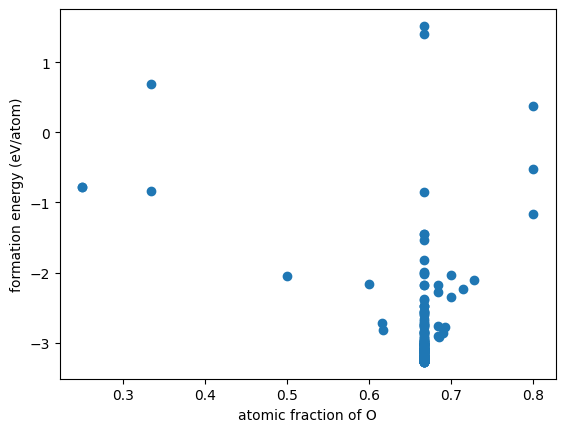

In [23]:
fig, ax = plt.subplots()
ax.scatter(si_o['x_O'], si_o['formation_energy'])
ax.set_xlabel('atomic fraction of O')
ax.set_ylabel('formation energy (eV/atom)')

Most entries sit at $x_O = 2/3$: that's SiO₂.
The lowest point of all is there too.

A few entries are above zero.
They are less stable than pure Si and O.

## Same composition, different structures

Let's keep only SiO₂:

In [24]:
sio2 = si_o[si_o['formula'] == 'SiO2']
print(len(sio2))

322


Hundreds of crystal structures, one composition.
Composition alone can't tell them apart.

Let's plot density against formation energy:

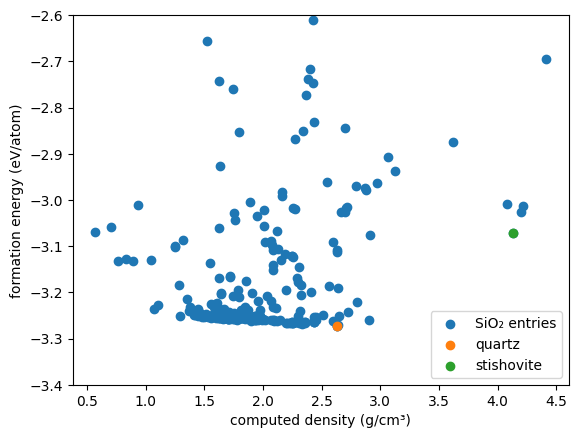

In [25]:
quartz_row = sio2[sio2['material_id'] == 'mp-7000']
stishovite_row = sio2[sio2['material_id'] == 'mp-6947']

fig, ax = plt.subplots()
ax.scatter(sio2['density'], sio2['formation_energy'], label='SiO₂ entries')
ax.scatter(quartz_row['density'], quartz_row['formation_energy'], label='quartz')
ax.scatter(stishovite_row['density'], stishovite_row['formation_energy'], label='stishovite')
ax.set_xlabel('computed density (g/cm³)')
ax.set_ylabel('formation energy (eV/atom)')
ax.set_ylim(-3.4, -2.6)  # zoom in on the most stable entries
ax.legend()

Quartz sits at the very bottom.
Stishovite is among the densest entries, and a little higher in energy.

In [26]:
print(quartz_row[['density', 'formation_energy']])
print(stishovite_row[['density', 'formation_energy']])

     density  formation_energy
23  2.634242         -3.272831
     density  formation_energy
22  4.134212          -3.07112


Stishovite is about 57% denser than quartz: 4.13 / 2.63 = 1.57.
Its formation energy is 0.20 eV/atom higher: −3.07 − (−3.27) = 0.20.

These energies are for 0 K and zero pressure.
There, quartz is the more stable form.

High pressure favors the denser crystal.
A meteor impact briefly makes that pressure, and stishovite can form.

# Summary

* The `structure` field returns a pymatgen `Structure`: a lattice plus atom species and positions.
* `as_dataframe` and `px.scatter_3d` plot the atoms; `aspectmode='data'` keeps the axes equal.
* The primitive cell is the smallest repeating cell; the conventional cell shows the symmetry.
* Some methods change an object in place; `make_supercell(..., in_place=False)` returns a new one.
* A feature is a number computed from a material, like the atomic fraction from `composition.get_atomic_fraction`.

## Further reading

* pymatgen, [Structure and Composition basics](https://pymatgen.org/usage.html)
* Plotly, [3D scatter plots in Python](https://plotly.com/python/3d-scatter-plots/)
* Materials Project, [Thermodynamic stability](https://docs.materialsproject.org/methodology/materials-methodology/thermodynamic-stability)
* The Materials Project data used here are shared under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).